## <div style="direction:rtl;text-align:right">  بخش سوم؛ پردازش و بازیابی ویدیو </div>

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#### <div style="direction:rtl;text-align:right"> سوال اول؛ بارگذاری و بررسی مشخصات ویدیو </div>

In [38]:
cap = cv2.VideoCapture("park_video.mp4")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
frame_width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
frame_height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
total_time = frame_count / fps

print(f'Frame Count: {frame_count}')
print(f'Frame Rate: {fps} FPS')
print(f'Frame Width: {frame_width} px')
print(f'Frame Height: {frame_height} px')
print(f'Video Time: {total_time} s')

cap.release()

Frame Count: 450.0
Frame Rate: 30.0 FPS
Frame Width: 1280.0 px
Frame Height: 720.0 px
Video Time: 15.0 s


<div style="direction:rtl;text-align:right">
در OpenCV با دستور Videocapture می‌توانیم ویدیو را بخوانیم.
<br/>
برای بدست آوردن هر یک از مشخصات  تصویر، OpenCV یک متود مخصوص دارد که مشخصه را گزارش می‌کند.
<br/>
فقط برای نمایش زمان ویدیو، تعداد کل فریم‌های تصویر را بر نرخ فریم تقسیم کردیم تا تعداد ثانیه‌های ویدیو بدست آید. سپس این مقدار را به دقیقه و ثانیه تبدیل کردیم.
</div>

#### <div style="direction:rtl;text-align:right"> سوال دوم؛ اضافه کردن نویز به ویدیو </div>

<div style="direction:rtl;text-align:right">از همان تابع ایجاد نویز نوشته شده در بخش دوم استفاده می‌کنیم.</div>

In [39]:
def salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()

    rand = np.random.rand(*image.shape[:2])

    noisy[rand < amount / 2] = 0
    noisy[rand > 1 - amount / 2] = 255

    return noisy

<div style="direction:rtl;text-align:right">
برای ایجاد خروجی ویدیوی نویزدار، باید اول کدک خروجی را مشخص کنیم. FourCC یک کد 4 بایتی است که برای تعیین کدک ویدیو استفاده می شود.
<br/>
کدک avc1 می‌تواند خروجی MP4 تولید کند و همچنین حجم خروجی نسبتا کمتری دارد.
</div>

In [40]:
fourcc = cv2.VideoWriter_fourcc(*'avc1')
frame_size = (int(frame_width),  int(frame_height))

<div style="direction:rtl;text-align:right">
برای تولید ویدیوی نویزدار، هر فریم را جداگانه میخوانیم، با تابع بالا نویز را به فریم اضافه می‌کنیم و در نهایت فریم نویزدار را در خروجی می‌نویسیم.
<br/>
این فرآیند را یک تابع جداگانه نوشتیم تا در سوالات بعدی نیز با همین تابع، سایر فیلترها را روی ویدیو‌ها اعمال کنیم.
</div>

In [41]:
def applyFilter(filter_func, cap, out):
    
    while True:    
        ret, frame = cap.read()
        # if frame is read correctly ret is True
        
        if not ret:
            break
        
        filtered_frame = filter_func(frame)
        out.write(filtered_frame)
    
    out.release()
    cap.release()

    return 'video successfully created!'

In [42]:
cap = cv2.VideoCapture("park_video.mp4")
out = cv2.VideoWriter('noisy_video.MP4', fourcc, fps, frame_size)

res = applyFilter(
    lambda frame: salt_pepper_noise(frame), 
    cap, out
)
print(f'noisy {res}')

noisy video successfully created!


<div style="direction:rtl;text-align:right">
در کد زیر هم هر دو ویدیوی اصلی و نویزدار دوباره خوانده شده‌اند، فریم 200 از هر دو ویدیو انتخاب و نمایش داده شده است.
</div>

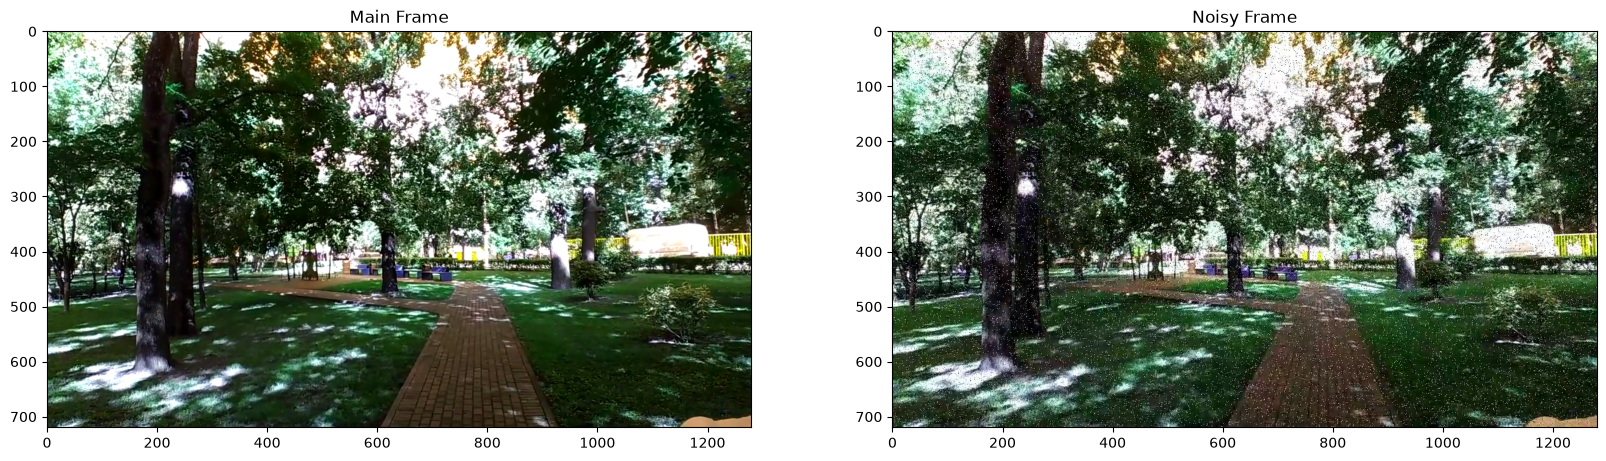

In [43]:
cap = cv2.VideoCapture("park_video.mp4")
cap.set(cv2.CAP_PROP_POS_FRAMES, 200)
ret, main_frame = cap.read()

cap2 = cv2.VideoCapture("noisy_video.mp4")
cap2.set(cv2.CAP_PROP_POS_FRAMES, 200)
ret, noisy_frame = cap2.read()

plt.figure(figsize=[20,10])
plt.subplot(121); plt.imshow(main_frame); plt.title('Main Frame');
plt.subplot(122); plt.imshow(noisy_frame); plt.title('Noisy Frame');

cap.release()
cap2.release()

#### <div style="direction:rtl;text-align:right"> سوال سوم؛ حذف نویز از ویدیو </div>

<div style="direction:rtl;text-align:right">
میانه زدیم ریده شد بهش
    <br/>
    <br/>

</div>

In [44]:
cap = cv2.VideoCapture("noisy_video.mp4")
out = cv2.VideoWriter('filtered_video_1.MP4', fourcc, fps, frame_size)

res = applyFilter(
    lambda frame: cv2.medianBlur(frame, 5), 
    cap, out
)
print(f'Filtered {res}')

Filtered video successfully created!


#### <div style="direction:rtl;text-align:right"> سوال چهارم؛ مقایسه روش‌های حذف نویز </div>

<div style="direction:rtl;text-align:right">
گوسین زدیم تر خورد بهش
    <br/>
<br/>
</div>

In [45]:
cap = cv2.VideoCapture("noisy_video.mp4")
out = cv2.VideoWriter('filtered_video_2.MP4', fourcc, fps, frame_size)

res = applyFilter(
    lambda frame: cv2.GaussianBlur(frame, (5, 5), 0), 
    cap, out
)
print(f'Filtered {res}')

Filtered video successfully created!


#### <div style="direction:rtl;text-align:right"> سوال پنجم؛ بررسی و تحلیل نتایج </div>

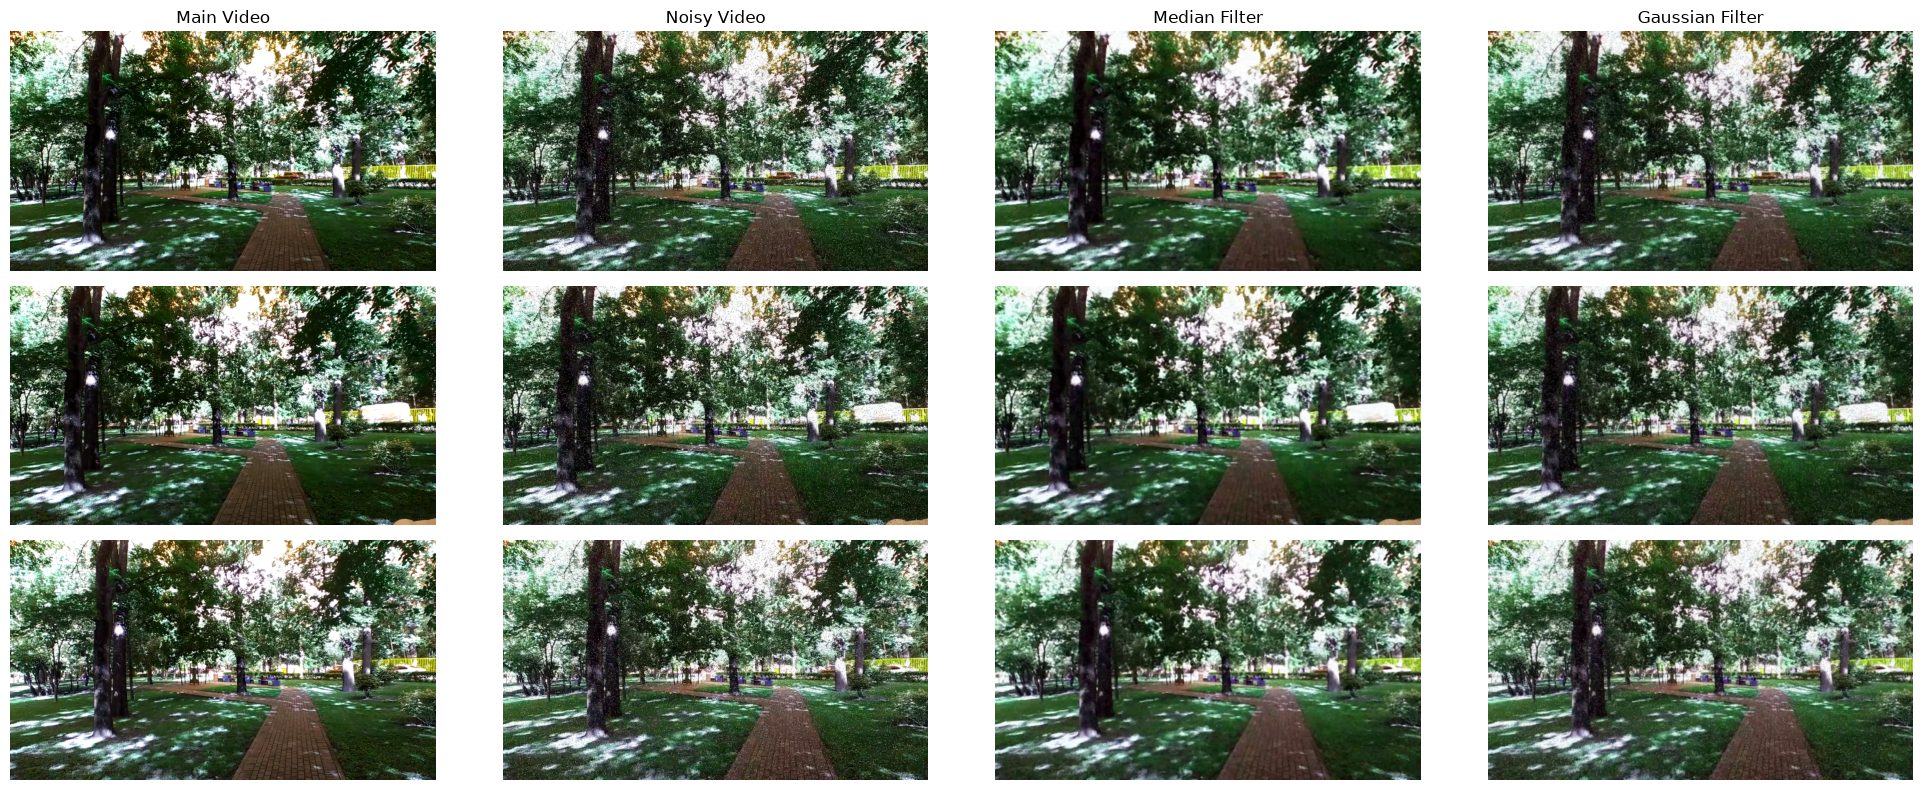

In [47]:
videos = [
    ("park_video.mp4", "Main Video"),
    ("noisy_video.mp4", "Noisy Video"),
    ("filtered_video_1.MP4", "Median Filter"),
    ("filtered_video_2.MP4", "Gaussian Filter"),
]
frame_no = [20, 200, 420]

fig, axes = plt.subplots(3, 4, figsize=(20, 8))

for i in range(3):
    for j, (video, title) in enumerate(videos):

        cap = cv2.VideoCapture(video)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_no[i])
        ret, frame = cap.read()
    
        axes[i, j].imshow(frame, vmin=0, vmax=255)
        if i == 0:
            axes[i, j].set_title(title)
        axes[i, j].axis("off")

        cap.release()

plt.tight_layout()
plt.show()

<div style="direction:rtl;text-align:right">
برای کاهش نور مصنوعی تصویر از دو روش متفاوت استفاده کردیم.
<br/>
در روش اول از تمامی مقادیر کانال value تصویر یک مقدار ثابت کم کردیم تا روشنایی تصویر کاهش پیدا کند. در اینصورت پیکسل‌هایی که مقادیر value کمتر از 70 داشتند به 0 و سیاه تبدیل شدند.
<br/>
در روش دوم برای جلوگیری از سیاه شدن پیکسل‌ها، تمامی مقادیر کانال value را در یک عدد کوچکتر از 1 ضرب کردیم. در اینصورت پیکسل‌هایی که از قبل مقداری روشنایی داشتند دیگر 0 نخواهند شد.
</div>

##### <div style="direction:rtl;text-align:right"> Histogram Equalization </div>

<div style="direction:rtl;text-align:right">
روش Histogram Stretching بازه‌ی شدت روشنایی تصویر را در کل محدوده 0 تا 255 گسترش می‌دهد. این کار بر اساس رابطه‌ی زیر انجام می‌شود؛
<div style="direction:rtl;text-align:left"> V_new = (V_old - V_min) / (V_max - V_min) * 255 </div>
پس از اصلاح، کمترین میزان روشنایی به صفر، و بیشترین میزان روشنایی به 255 نگاشت می‌یابد. همچنین سایر مقادیر نیز به نسبت و بصورت خطی تبدیل می‌شوند. 
    <br/>
    در واقع توزیع هیستوگرام تصویر را کشیده و پخش می‌کند.
</div>

##### <div style="direction:rtl;text-align:right"> Histogram Stretching </div>

<div style="direction:rtl;text-align:right">
واضح است که کاهش روشنایی تصویر، بر جداسازی تمیزتر رنگ‌های اثر منفی می‌گذارد چراکه مقادیر پیکسل‌ها را به یکدیگر نزدیک‌تر می‌کند.
    <br/>
اما در خصوص تصاویر بهبود یافته، تصویری که با روش Histogram Equalization اصلاح شده نتیجه‌ی بدتری دارد. در این تصویر برخی نقاط سبز رنگ به سمت سیاهی رفته و انتخاب نشده‌اند.
    <br/>
از طرفی تصویر بهبود یافته با روش Histogram Stretching وضعیت مطلوبی دارد. در این تصویر محدوده‌ی تشخیص داده شده اگرچه کامل نیست اما به نسبت بهتر و قابل قبول است.
</div>